# Sensitivity and robustness analyses

This notebook stress-tests the frozen model-training and primary-evaluation result against six prespecified
robustness questions, restricted to `minimal_cox` and `spline_cox` (the same Tier 1/2 pair the
frozen contract names for calibration drift), both loaded from the single frozen model-training
registry. **Every number here is reported alongside the frozen primary result, never in place of
it**: no primary model is refit, no cohort/split/endpoint/horizon
changes, and no classification rule from the evaluation, optimization, or explainability analyses is revised. TTNT-D remains supportive and is
never described as a validated progression surrogate.

The analysis follows the project's frozen sensitivity-analysis contract.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from crc_folfox.sensitivity.workflow import run_sensitivity_workflow

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
ANALYSIS_DIRECTORY = PROJECT_ROOT / "analysis" / "out" / "current"

result = run_sensitivity_workflow(ANALYSIS_DIRECTORY)

/Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC/.venv/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC/.venv/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC/.venv/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC/.venv/lib/pyt

## Verified handoff

The workflow re-verifies the cleaned-dataset and preprocessing artifact hashes and the frozen model-training manifest and
every registered `minimal_cox`/`spline_cox` bundle hash before any sensitivity is computed, and
re-verifies them unchanged after publication -- no upstream artifact is mutated by this notebook.

In [2]:
import json

assert result.artifacts is not None
manifest = json.loads(
    (result.artifacts.directory / "sensitivity_manifest.json").read_text(encoding="utf-8")
)
display({"workflow": "sensitivity and robustness analyses", **{key: manifest[key] for key in ("input_hashes", "software_versions")}})

{'workflow': 'sensitivity and robustness analyses',
 'input_hashes': {'analysis_dataset.csv': '6b9e28099f547150324b33be900d228d22b411b7dbe0d68e1e08551aaab6740e',
  'data_dictionary.json': '74afd2302e93585bda59f4ecb01b536da05c0a44da14f07f66e8b660eeb27496',
  'feature_manifest.json': 'cc891bcdca2b06179dd33e4bc55160e0e048557059e57b0b02789c7b18dc0f73',
  'fit_summary.csv': 'dfb77a84220741ad94e1362a90eaaa8c2240980ddd7c59ef0ed039548d60ad9b',
  'model_registry.json': '2695e55ae3ed97a9e98d5ff419544dafb7ee21e9bb65c6e6ca4ae6bd3770596f',
  'run_manifest.json': 'd11982f0e9cd7f740cae7432744fa23aba336d944f7236a2f10429e775b84bfd',
  'training_report.md': '393ef27916c7182a27d5a04f38c8684f62acc6e8b75776321fdbcdf055ac9875',
  'tuning_summary.csv': 'cdc1a195c921f30c54c81059276e5262041c75697265a608d8781720d2c42115'},
 'software_versions': {'lifelines': '0.30.3',
  'numpy': '2.5.1',
  'pandas': '2.3.3',
  'statsmodels': '0.14.6'}}

## 1. Sequencing-lag sensitivity (headline figure)

The four locked thresholds, in order: **by FOLFOX initiation → ≤90d → ≤180d → ≤365d →
unrestricted**. Cohort/event/entry-distribution support is shown for every threshold overall and by
centre; the pooled `minimal_cox` sensitivity estimate is added only where the imported primary-evaluation
reporting-status gate is met. No threshold is ever chosen or relabelled after inspecting
performance -- the four thresholds are hardcoded.

In [3]:
display(result.sequencing_lag_support)
display(result.sequencing_lag_km)
display(
    result.sequencing_lag_pooled_minimal_cox[
        result.sequencing_lag_pooled_minimal_cox["metric"].isin(
            ["concordance", "ibs", "brier_365", "brier_730"]
        )
    ]
)

,endpoint,threshold,group,n_patients,n_events,entry_mean,entry_median,entry_min,entry_max
0,OS,by_folfox,DFCI,23,6,0.000000,0.0,0.0,0.0
1,OS,90d,DFCI,89,40,32.382022,31.0,0.0,88.0
2,OS,180d,DFCI,120,61,59.125000,44.5,0.0,178.0
3,OS,365d,DFCI,150,78,101.913333,66.5,0.0,356.0
4,OS,unrestricted,DFCI,227,129,425.383260,163.0,0.0,3782.0
5,OS,by_folfox,MSK,11,1,0.000000,0.0,0.0,0.0
6,OS,90d,MSK,142,65,38.563380,36.5,0.0,90.0
7,OS,180d,MSK,179,90,57.351955,48.0,0.0,172.0
8,OS,365d,MSK,214,109,93.032710,54.5,0.0,358.0
9,OS,unrestricted,MSK,330,178,421.027273,141.5,0.0,3978.0


,endpoint,threshold,group,n_patients,survival_365,survival_730,status,reason
0,OS,by_folfox,DFCI,23,0.854067,0.803828,ok,
1,OS,90d,DFCI,89,0.867756,0.705111,ok,
2,OS,180d,DFCI,120,0.858855,0.670921,ok,
3,OS,365d,DFCI,150,0.859947,0.660578,ok,
4,OS,unrestricted,DFCI,227,0.859947,0.645460,ok,
5,OS,by_folfox,MSK,11,0.909091,0.909091,ok,
6,OS,90d,MSK,142,0.855047,0.686079,ok,
7,OS,180d,MSK,179,0.844656,0.641076,ok,
8,OS,365d,MSK,214,0.850336,0.645231,ok,
9,OS,unrestricted,MSK,330,0.850336,0.646062,ok,


,endpoint,threshold,centre,model,metric,estimate,ci_lower,ci_upper,n_eligible,n_events,reporting_status,reason
0,OS,by_folfox,DFCI,minimal_cox,concordance,0.791667,0.587617,0.952104,23,6,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."
1,OS,by_folfox,DFCI,minimal_cox,ibs,0.139719,0.038534,0.266611,23,4,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."
4,OS,by_folfox,DFCI,minimal_cox,brier_365,0.124959,0.002799,0.267898,23,3,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."
5,OS,by_folfox,DFCI,minimal_cox,brier_730,0.126576,0.043554,0.226684,23,4,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."
10,OS,90d,DFCI,minimal_cox,concordance,0.678098,0.595780,0.754635,89,40,estimable,
...,...,...,...,...,...,...,...,...,...,...,...,...
285,TTNT-D,365d,VICC,minimal_cox,brier_730,0.161061,0.079405,0.260464,27,18,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."
290,TTNT-D,unrestricted,VICC,minimal_cox,concordance,0.632287,0.465934,0.766030,32,24,estimable_imprecise,"insufficient_event_free,precision_target_missed"
291,TTNT-D,unrestricted,VICC,minimal_cox,ibs,0.215601,0.143364,0.317898,31,22,estimable_imprecise,"insufficient_event_free,precision_target_missed"
294,TTNT-D,unrestricted,VICC,minimal_cox,brier_365,0.253414,0.182692,0.356641,27,13,estimable_imprecise,"insufficient_events,insufficient_event_free,pr..."


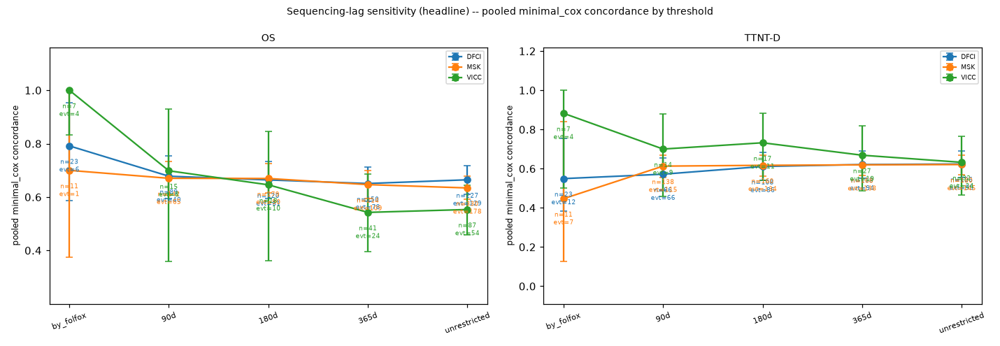

In [4]:
display(Image(filename=str(result.artifacts.directory / "figures" / "sequencing_lag_headline.png")))

## 2. Delayed-entry / independent-truncation assumption checks

A left-truncation-aware **conditional Kendall's tau** (Martin–Betensky, 2005), per institution and
as one centre-stratified pooled row, with the required descriptive-only conclusion below. **Failing
to reject quasi-independence does not prove independent truncation.**

In [5]:
display(result.truncation_kendall_tau)
display(result.entry_time_distribution)
display(result.km_by_entry_quartile)
display(result.entry_exclusion_summary)

,endpoint,stratum,tau,ci_lower,ci_upper,p_value,n_comparable_pairs,n_patients,n_events,reporting_status,reason,conclusion
0,OS,DFCI,-0.108454,-0.221818,0.000446,0.059325,11083,227,129,estimable,,Evidence against quasi-independence was detect...
1,OS,MSK,-0.088977,-0.179481,0.004235,0.054980,23568,330,178,estimable,,Evidence against quasi-independence was detect...
2,OS,VICC,-0.091463,-0.266624,0.094728,0.329220,1312,87,54,estimable,,Evidence against quasi-independence was detect...
3,OS,pooled,-0.095070,-0.164194,-0.027356,0.006227,35963,644,361,estimable,,Evidence against quasi-independence was detect...
4,TTNT-D,DFCI,-0.168090,-0.308092,-0.034940,0.015138,5152,126,95,estimable,,Evidence against quasi-independence was detect...
5,TTNT-D,MSK,-0.124448,-0.228999,-0.016140,0.022835,11330,180,145,estimable,,Evidence against quasi-independence was detect...
6,TTNT-D,VICC,-0.349776,-0.603311,-0.046822,0.015165,223,32,24,estimable,,Evidence against quasi-independence was detect...
7,TTNT-D,pooled,-0.140916,-0.222340,-0.054395,0.001182,16705,338,264,estimable,,Evidence against quasi-independence was detect...


,endpoint,group,n_patients,entry_p0,entry_p10,entry_p25,entry_p50,entry_p75,entry_p90,entry_p100
0,OS,DFCI,227,0.0,1.2,43.00,163.0,618.50,1227.8,3782.0
1,OS,MSK,330,0.0,20.9,43.25,141.5,557.75,1267.0,3978.0
2,OS,VICC,87,0.0,11.0,210.00,398.0,798.00,1289.2,3941.0
3,OS,All,644,0.0,14.0,45.00,193.5,620.50,1260.0,3978.0
4,TTNT-D,DFCI,126,0.0,0.0,16.00,49.0,117.75,248.5,1569.0
5,TTNT-D,MSK,180,0.0,10.0,26.00,48.0,88.25,209.1,1689.0
6,TTNT-D,VICC,32,0.0,0.0,10.50,138.5,289.25,401.1,867.0
7,TTNT-D,All,338,0.0,0.0,21.00,49.0,113.00,289.3,1689.0


,endpoint,entry_quartile,n_patients,n_events,entry_min,entry_max,survival_365,survival_730,status
0,OS,0,161,68,0.0,45.0,0.888872,0.723482,ok
1,OS,1,161,93,45.0,192.0,0.817063,0.587710,ok
2,OS,2,161,94,195.0,619.0,0.877728,0.623986,ok
3,OS,3,161,106,625.0,3978.0,NaN,0.832648,ok
4,TTNT-D,0,85,57,0.0,21.0,0.437040,0.305181,ok
5,TTNT-D,1,85,74,21.0,49.0,0.188204,0.125469,ok
6,TTNT-D,2,84,73,49.0,113.0,0.261793,0.142796,ok
7,TTNT-D,3,84,60,113.0,1689.0,0.345000,0.140499,ok


,endpoint,n_total_patients,n_entry_at_or_after_exit,median_entry_lag_days
0,OS,678,34,215.0


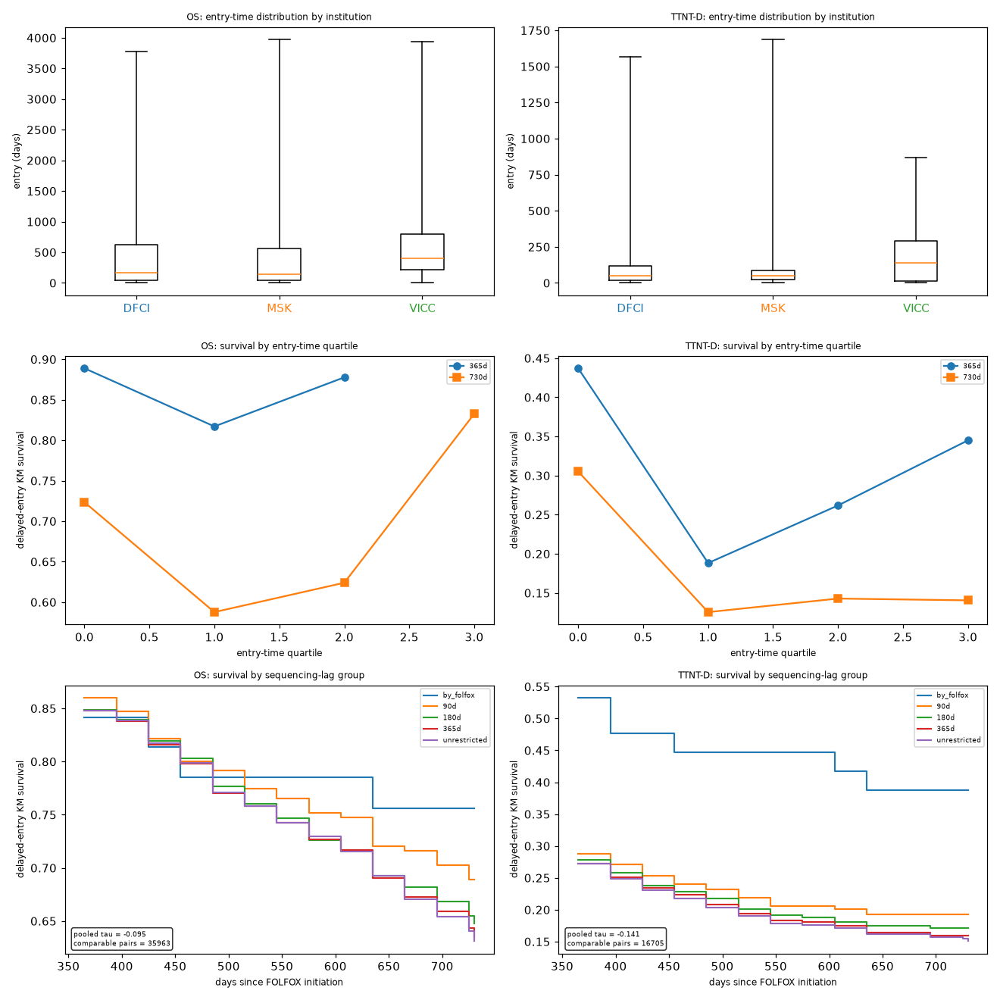

In [6]:
display(Image(filename=str(result.artifacts.directory / "figures" / "truncation_diagnostic.png")))

## 3. Complete-case assessment-subset sensitivity

Full-population-versus-complete-case comparison, reusing the frozen `minimal_cox`/`spline_cox`
predictions with **no refit** and nuisance/censoring weights re-estimated *within* the complete-case
subset. This tests whether reported performance changes among patients with complete predictor
data; it does **not** test how model fitting would change without imputation.

In [7]:
display(
    result.complete_case[
        [
            "endpoint",
            "design",
            "centre",
            "model",
            "metric",
            "n_patients_full",
            "full_estimate",
            "full_reporting_status",
            "n_patients_complete_case",
            "complete_case_estimate",
            "complete_case_reporting_status",
        ]
    ]
)

,endpoint,design,centre,model,metric,n_patients_full,full_estimate,full_reporting_status,n_patients_complete_case,complete_case_estimate,complete_case_reporting_status
0,OS,iecv,DFCI,minimal_cox,concordance,227,0.668727,estimable,166,0.667196,estimable
1,OS,iecv,DFCI,minimal_cox,ibs,227,0.167130,estimable,166,0.134431,estimable
2,OS,iecv,DFCI,minimal_cox,auc_365,227,0.675138,estimable_imprecise,166,0.721144,estimable_imprecise
3,OS,iecv,DFCI,minimal_cox,auc_730,227,0.682666,estimable,166,0.684566,estimable
4,OS,iecv,DFCI,minimal_cox,brier_365,227,0.097455,estimable_imprecise,166,0.064634,estimable_imprecise
...,...,...,...,...,...,...,...,...,...,...,...
235,TTNT-D,pooled,VICC,spline_cox,brier_730,32,0.205655,estimable_imprecise,29,0.196665,estimable_imprecise
236,TTNT-D,pooled,VICC,spline_cox,slope_365,32,0.468749,estimable_imprecise,29,0.413254,estimable_imprecise
237,TTNT-D,pooled,VICC,spline_cox,slope_730,32,0.491954,estimable_imprecise,29,0.795408,estimable_imprecise
238,TTNT-D,pooled,VICC,spline_cox,citl_365,32,-0.192669,estimable_imprecise,29,-0.102025,estimable_imprecise


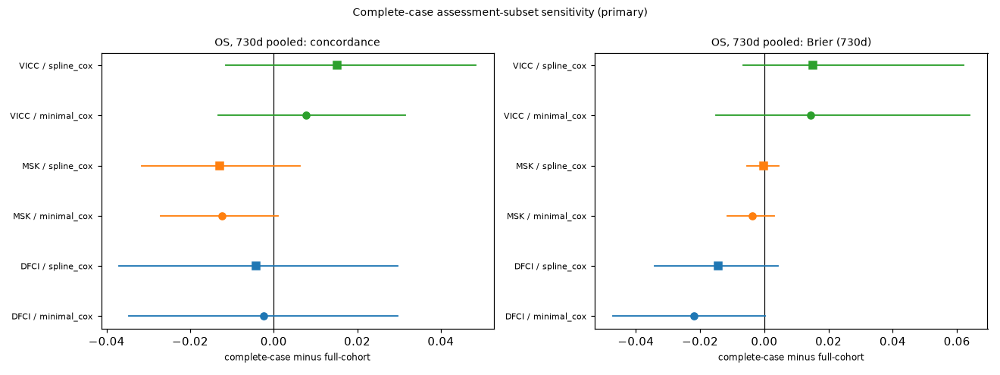

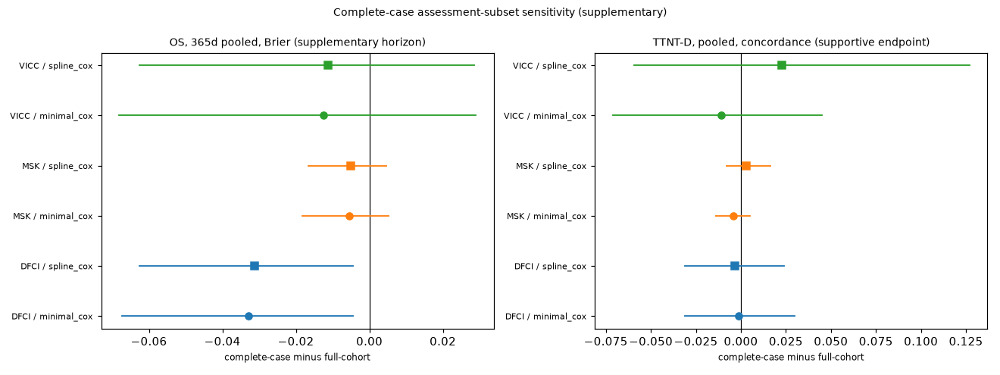

In [8]:
display(
    Image(filename=str(result.artifacts.directory / "figures" / "complete_case_forest_primary.png"))
)
display(
    Image(
        filename=str(
            result.artifacts.directory / "figures" / "complete_case_forest_supplementary.png"
        )
    )
)

## 4. Supportive endpoint robustness

Every prespecified OS sensitivity above is repeated identically for TTNT-D on its own frozen
eligible population. Each comparison is classified **concordant** / **discordant** /
**indeterminate** using direction, interval, materiality threshold, and reporting status jointly --
never a p-value alone. **TTNT-D remains supportive and never overturns an OS conclusion**, regardless
of classification.

In [9]:
display(result.endpoint_robustness)
if len(result.endpoint_robustness):
    display(result.endpoint_robustness["concordance_classification"].value_counts())

,sensitivity,population_view,design,centre,model,metric,os_effect,os_status,ttnt_effect,ttnt_status,concordance_classification,reason
0,complete_case,native,iecv,DFCI,minimal_cox,concordance,-0.001531,estimable,0.002634,estimable,discordant,
1,complete_case,native,iecv,DFCI,minimal_cox,ibs,-0.032699,estimable,0.002990,estimable,discordant,
2,complete_case,native,iecv,DFCI,minimal_cox,auc_365,0.046006,estimable_imprecise,0.009815,estimable,indeterminate,insufficient_reporting_status
3,complete_case,native,iecv,DFCI,minimal_cox,auc_730,0.001901,estimable,0.009459,estimable,concordant,
4,complete_case,native,iecv,DFCI,minimal_cox,brier_365,-0.032822,estimable_imprecise,-0.000195,estimable,indeterminate,insufficient_reporting_status
...,...,...,...,...,...,...,...,...,...,...,...,...
119,complete_case,native,pooled,VICC,spline_cox,citl_730,0.106019,estimable_imprecise,0.207089,estimable_imprecise,indeterminate,insufficient_reporting_status
120,truncation_kendall_tau,native,,DFCI,,tau,-0.108454,estimable,-0.168090,estimable,concordant,
121,truncation_kendall_tau,native,,MSK,,tau,-0.088977,estimable,-0.124448,estimable,discordant,material_on_only_one_endpoint
122,truncation_kendall_tau,native,,VICC,,tau,-0.091463,estimable,-0.349776,estimable,discordant,material_on_only_one_endpoint


concordance_classification
indeterminate    73
discordant       35
concordant       16
Name: count, dtype: int64

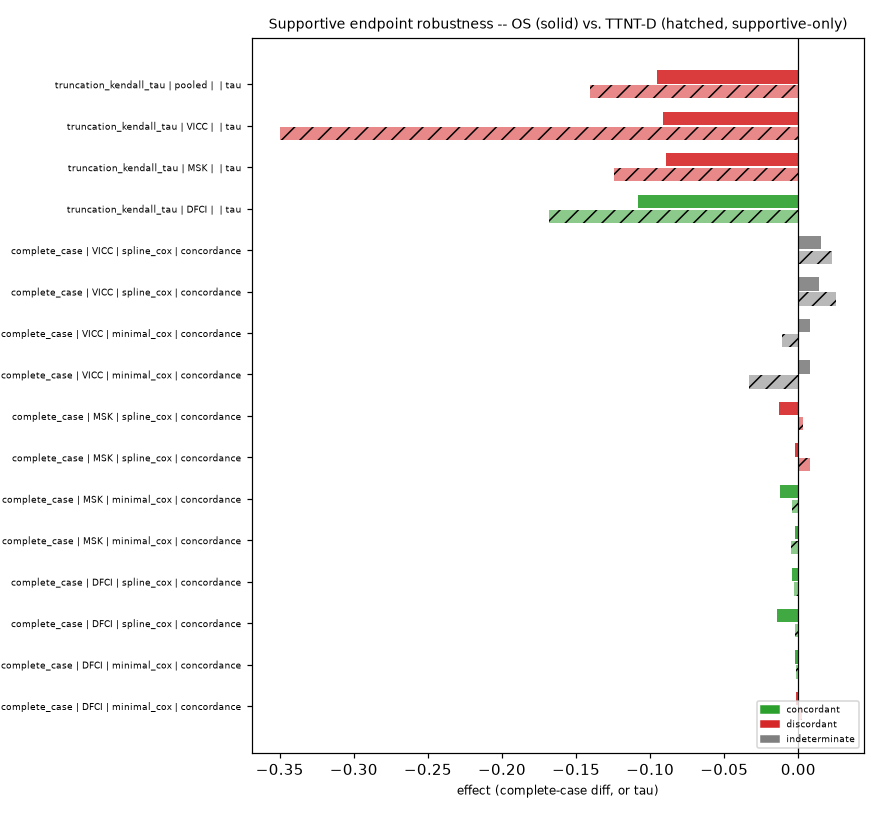

In [10]:
display(
    Image(
        filename=str(result.artifacts.directory / "figures" / "endpoint_robustness_comparison.png")
    )
)

## 5. Calibration drift and local recalibration

The fixed four-step decomposition: untouched → intercept-only → intercept-plus-slope → exploratory
10/20/30% local-adaptation learning curve, on the institution-held-out (`iecv`) prediction. Every
recalibrated row is labelled `local_adaptation`, never external validation, and reported
before-and-after against the frozen untouched prediction. An infeasible fraction (VICC is the
anticipated case) is reported explicitly, never manufactured.

In [11]:
display(result.calibration_drift)
display(result.local_recalibration)

,endpoint,centre,model,step,horizon,slope_before,citl_before,slope_after,citl_after,n_eligible,n_events,reason,analysis_status
0,OS,DFCI,minimal_cox,untouched,365.0,1.078809,0.475061,1.078809,4.750613e-01,150,16,,
1,OS,DFCI,minimal_cox,intercept_only,365.0,1.078809,0.475061,1.078809,-3.053113e-16,150,16,,local_adaptation
2,OS,DFCI,minimal_cox,intercept_slope,365.0,1.078809,0.475061,1.000000,-2.886912e-08,150,16,,local_adaptation
3,OS,DFCI,minimal_cox,untouched,730.0,0.974309,0.335969,0.974309,3.359693e-01,184,51,,
4,OS,DFCI,minimal_cox,intercept_only,730.0,0.974309,0.335969,0.974309,0.000000e+00,184,51,,local_adaptation
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,TTNT-D,VICC,spline_cox,intercept_only,365.0,0.364229,-0.360966,0.364229,-5.551115e-17,27,13,,local_adaptation
68,TTNT-D,VICC,spline_cox,intercept_slope,365.0,0.364229,-0.360966,1.000000,8.226204e-07,27,13,,local_adaptation
69,TTNT-D,VICC,spline_cox,untouched,730.0,0.385938,0.039199,0.385938,3.919901e-02,31,22,,
70,TTNT-D,VICC,spline_cox,intercept_only,730.0,0.385938,0.039199,0.386103,1.174950e-07,31,22,,local_adaptation


,endpoint,centre,model,fraction,horizon,n_adaptation,n_adaptation_events,n_evaluation,n_evaluation_events,feasible,reason,adaptation_intercept,slope_before,citl_before,slope_after,citl_after,analysis_status
0,OS,DFCI,minimal_cox,0.1,365.0,23,13,204,116,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation
1,OS,DFCI,minimal_cox,0.1,730.0,23,13,204,116,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation
2,OS,DFCI,minimal_cox,0.2,365.0,46,26,181,103,True,,0.817271,1.494328,0.349442,1.494328,-0.46783,local_adaptation
3,OS,DFCI,minimal_cox,0.2,730.0,46,26,181,103,True,,0.028607,1.031071,0.419656,1.031071,0.391049,local_adaptation
4,OS,DFCI,minimal_cox,0.3,365.0,68,39,159,90,True,,0.556819,0.69466,0.429207,0.69466,-0.127612,local_adaptation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,TTNT-D,VICC,spline_cox,0.1,730.0,3,2,29,22,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation
68,TTNT-D,VICC,spline_cox,0.2,365.0,7,5,25,19,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation
69,TTNT-D,VICC,spline_cox,0.2,730.0,7,5,25,19,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation
70,TTNT-D,VICC,spline_cox,0.3,365.0,9,7,23,17,False,insufficient_adaptation_or_evaluation_support,,,,,,local_adaptation


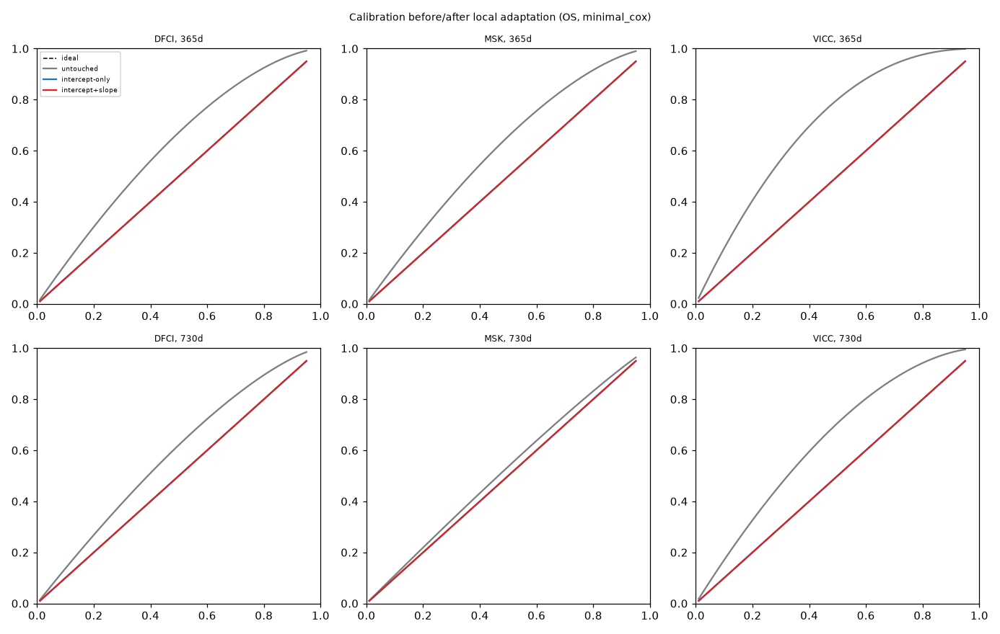

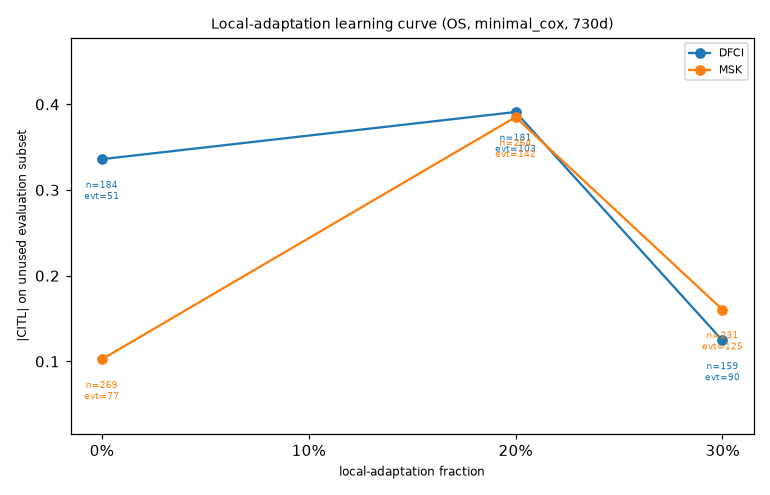

In [12]:
display(
    Image(filename=str(result.artifacts.directory / "figures" / "calibration_drift_curves.png"))
)
display(
    Image(
        filename=str(result.artifacts.directory / "figures" / "local_adaptation_learning_curve.png")
    )
)

## 6. No-information reference and scaled Brier score

A clearly labelled **descriptive aid**: `scaled_brier = 1 - Brier_model / Brier_KM` against the
delayed-entry Kaplan–Meier no-information reference. Raw Brier/IBS values remain valid for
comparing models on the same patients; this is **not** retrofitted into the frozen primary-evaluation metric
hierarchy.

In [13]:
display(result.scaled_brier)

,endpoint,design,centre,model,metric,model_brier,no_information_brier,scaled_brier,reason,descriptive_only
0,OS,iecv,DFCI,minimal_cox,ibs,0.167130,0.170606,0.020373,,True
1,OS,iecv,DFCI,minimal_cox,brier_365,0.097455,0.100270,0.028066,,True
2,OS,iecv,DFCI,minimal_cox,brier_730,0.202202,0.218454,0.074395,,True
3,OS,pooled,DFCI,minimal_cox,ibs,0.168202,0.170606,0.014091,,True
4,OS,pooled,DFCI,minimal_cox,brier_365,0.098518,0.100270,0.017471,,True
...,...,...,...,...,...,...,...,...,...,...
67,TTNT-D,iecv,VICC,spline_cox,brier_365,0.305826,0.312930,0.022704,,True
68,TTNT-D,iecv,VICC,spline_cox,brier_730,0.213862,0.213945,0.000390,,True
69,TTNT-D,pooled,VICC,spline_cox,ibs,0.236311,0.264598,0.106904,,True
70,TTNT-D,pooled,VICC,spline_cox,brier_365,0.279911,0.312930,0.105518,,True


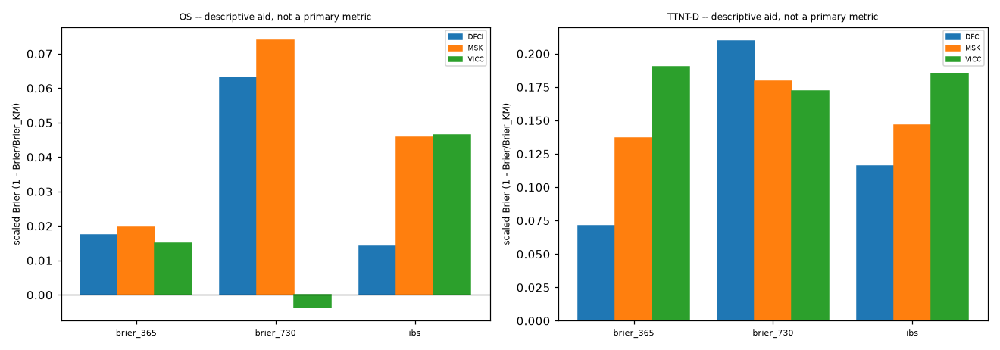

In [14]:
display(Image(filename=str(result.artifacts.directory / "figures" / "scaled_brier_reference.png")))

## Canonical artifacts and privacy scan

In [15]:
published = sorted(p.name for p in result.artifacts.directory.iterdir())
display(published)
figure_files = sorted(p.name for p in (result.artifacts.directory / "figures").glob("*.png"))
display(figure_files)

['calibration_drift.csv',
 'complete_case_assessment_subset.csv',
 'delayed_entry_survival_by_entry_quartile.csv',
 'entry_at_or_after_exit_summary.csv',
 'entry_time_distribution.csv',
 'figures',
 'local_recalibration.csv',
 'scaled_brier.csv',
 'sensitivity_manifest.json',
 'sensitivity_report.md',
 'sequencing_lag_km.csv',
 'sequencing_lag_km_curve.csv',
 'sequencing_lag_pooled_minimal_cox.csv',
 'sequencing_lag_support.csv',
 'supportive_endpoint_robustness.csv',
 'truncation_kendall_tau.csv']

['calibration_drift_curves.png',
 'complete_case_forest_primary.png',
 'complete_case_forest_supplementary.png',
 'endpoint_robustness_comparison.png',
 'local_adaptation_learning_curve.png',
 'scaled_brier_reference.png',
 'sequencing_lag_headline.png',
 'truncation_diagnostic.png']